# Lab 6: Localization (odometry)

Fayozbek Yusupov, ID 240061

The robot drives the "61" from Lab 1 with motors and timers. A parallel task counts the odometry with the formulas from the lecture (the blocks from `Localization_demo.qrs`) and writes `x,y,time` to a file in a loop with a 5 ms timer. I ran the same program in the simulator and on the real robot; the only differences are the wheel radius `r` and the base `B` of each robot, the file name, and the marker, which exists only in the simulator.

Upload `odometry_data_sim.txt` and `odometry_data_real.txt` in the next cell.

In [1]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select BOTH txt files

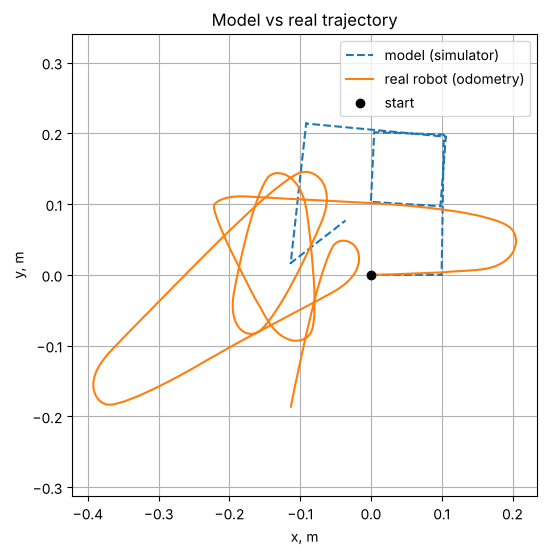

In [2]:
x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)

# 1. Trajectories on one plot
plt.figure(figsize=(6, 6))
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Model vs real trajectory')
plt.show()

In the simulator the robot drew the 61. In the plot it is upside down, because x is the direction the robot faced at the start. The real robot made loops instead, because with the same powers and timers it turned much more than 90 degrees at every turn.

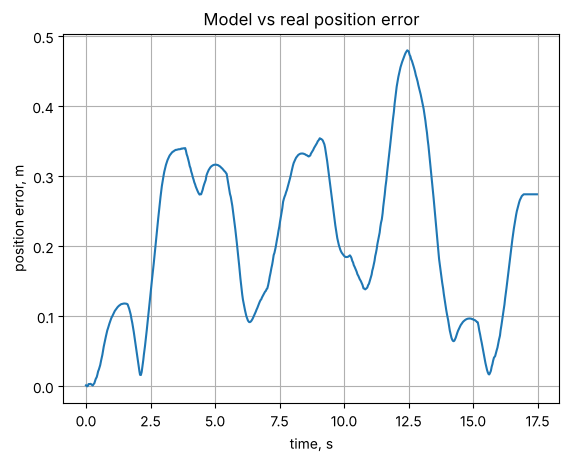

Final odometry error (sim vs real): 0.3 m
Max error: 0.5 m


In [3]:
# 2. Error over time (simulator resampled onto the real-robot timestamps)
t_s, t_r = t_s - t_s[0], t_r - t_r[0]
xs_i = np.interp(t_r, t_s, x_s)
ys_i = np.interp(t_r, t_s, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)

plt.plot(t_r / 1000, err)
plt.xlabel('time, s'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('Model vs real position error')
plt.show()

print(f'Final odometry error (sim vs real): {err[-1]:.1f} m')
print(f'Max error: {err.max():.1f} m')

## Measured end point

Before the run I put a mark A under the centre of the robot and a mark B 1 m behind it, on the line of the start direction. After the run I put a mark C under the centre of the robot and measured with a tape: C is 39 cm behind A along this line and 9 cm to the right of it (A–C = 39 cm, B–C = 61 cm). x is the start direction and y is to the left, so the real end point is x = -0.39 m, y = -0.09 m.

In [4]:
x_tape = -0.390                       # measured with a tape, m
y_tape = -0.090

print(f'Odometry (last line): x = {x_r[-1]:.3f} m, y = {y_r[-1]:.3f} m')
print(f'Tape:                 x = {x_tape:.3f} m, y = {y_tape:.3f} m')
print(f'Difference: {np.hypot(x_r[-1] - x_tape, y_r[-1] - y_tape):.3f} m')

Odometry (last line): x = -0.113 m, y = -0.186 m
Tape:                 x = -0.390 m, y = -0.090 m
Difference: 0.293 m


## Conclusions

The real trajectory diverges from the simulator already at the first turn: with the same powers and timers the real robot turned about 160° instead of 90° (by its own encoders) and drove 2.9 m instead of 1.2 m, so it made loops instead of the 61. This is the "unequal wheels / motors" error from the lecture: the real motors are much faster than the simulated ones, and the right motor is faster than the left one (my Week 5 k_e: 0.658 against 0.714), so even the straight pieces bend. Because heading error dominates, every too large turn sends the rest of the path in a new direction, so the final error is 0.3 m and the max error is 0.5 m. The odometry is also wrong by itself: the last line of `odometry_data_real.txt` says x = -0.11 m, y = -0.19 m, but the tape shows x = -0.39 m, y = -0.09 m, 0.29 m away, most likely because of wheel slip in the fast turns in place. The robot does not know it is wrong, because it only counts wheel rotations and slip is invisible to the encoders.